# Comparação estatística da recompra

As taxas de recompra diferem entre avaliações boas e ruins? Aplica teste Z bilateral e intervalo de Newcombe de 95%, sem interpretação causal.

In [1]:
from pathlib import Path
import pandas as pd


In [2]:
RAIZ_PROJETO = next(
    (
        pasta
        for pasta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (pasta / 'executar_pipeline.py').is_file()
        and (pasta / 'src').is_dir()
    ),
    None
)

if RAIZ_PROJETO is None:
    raise FileNotFoundError(
        'Execute o notebook dentro da pasta do projeto.'
    )

caminho_tabela = (
    RAIZ_PROJETO
    / 'outputs'
    / 'tabelas'
    / 'parquet'
    / '06_comparacao_taxas_recompra.parquet'
)

df_comparacao = pd.read_parquet(caminho_tabela)

display(df_comparacao)


,grupo,total_clientes,clientes_que_recompraram,clientes_que_nao_recompraram,taxa_recompra
0,Geral,82502,2534,79968,0.030714
1,Ruim,11128,277,10851,0.024892
2,Neutra,6972,181,6791,0.025961
3,Boa,64233,1920,62313,0.029891
4,Qualquer avaliação,82333,2378,79955,0.028883
5,Sem avaliação,169,156,13,0.923077


In [3]:
df_grupos = (
    df_comparacao
    .set_index('grupo')
    .loc[
        ['Boa', 'Ruim'],
        [
            'total_clientes',
            'clientes_que_recompraram',
            'clientes_que_nao_recompraram'
        ]
    ]
    .copy()
)

assert df_grupos.index.is_unique
assert df_grupos.notna().all().all()
assert df_grupos.ge(0).all().all()
assert df_grupos.mod(1).eq(0).all().all()
assert df_grupos['total_clientes'].gt(0).all()
assert (
    df_grupos['clientes_que_recompraram']
    + df_grupos['clientes_que_nao_recompraram']
).eq(df_grupos['total_clientes']).all()

df_grupos['taxa_recompra'] = (
    df_grupos['clientes_que_recompraram']
    / df_grupos['total_clientes']
)

display(
    df_grupos.style.format({
        'taxa_recompra': '{:.2%}'
    })
)


,total_clientes,clientes_que_recompraram,clientes_que_nao_recompraram,taxa_recompra
grupo,,,,
Boa,64233,1920,62313,2.99%
Ruim,11128,277,10851,2.49%


In [4]:
taxa_boa = df_grupos.loc['Boa', 'taxa_recompra']
taxa_ruim = df_grupos.loc['Ruim', 'taxa_recompra']

diferenca_pp = (taxa_boa - taxa_ruim) * 100

print(
    f'Diferença entre avaliações boas e ruins: '
    f'{diferenca_pp:.2f} pontos percentuais'
)


Diferença entre avaliações boas e ruins: 0.50 pontos percentuais


In [5]:
total_recompras = df_grupos['clientes_que_recompraram'].sum()

total_clientes = df_grupos['total_clientes'].sum()

# Estima uma taxa comum, supondo que os grupos tenham a mesma
# probabilidade de recompra, conforme a hipótese nula.
taxa_conjunta = total_recompras / total_clientes

df_verificacao = df_grupos[['total_clientes']].copy()

df_verificacao['recompras_esperadas'] = (
    df_verificacao['total_clientes'] * taxa_conjunta
)

# Calcula quantos clientes esperaríamos sem recompra.
df_verificacao['nao_recompras_esperadas'] = (
    df_verificacao['total_clientes'] * (1 - taxa_conjunta)
)

display(df_verificacao.round(2))

contagens_suficientes = (
    df_verificacao[
        ['recompras_esperadas', 'nao_recompras_esperadas']
    ]
    .ge(10)
    .all()
    .all()
)

print(
    'Contagens esperadas atendem ao critério:',
    contagens_suficientes
)


,total_clientes,recompras_esperadas,nao_recompras_esperadas
grupo,,,
Boa,64233,1872.59,62360.41
Ruim,11128,324.41,10803.59


Contagens esperadas atendem ao critério: True


In [6]:
from statsmodels.stats.proportion import proportions_ztest

# Só prossegue se a verificação anterior das contagens passou.
if not contagens_suficientes:
    raise ValueError(
        'As contagens não atendem ao critério adotado. '
        'Revise a escolha do teste antes de continuar.'
    )


recompras = df_grupos.loc[
    ['Boa', 'Ruim'],
    'clientes_que_recompraram'
].to_numpy()

quantidades = df_grupos.loc[
    ['Boa', 'Ruim'],
    'total_clientes'
].to_numpy()

# Executa o teste e recebe dois resultados.
estatistica_z, p_valor = proportions_ztest(
    count=recompras,          # Quantidade de clientes que recompraram.
    nobs=quantidades,         # Total de clientes de cada grupo.
    value=0,                 # H₀: diferença entre as proporções igual a zero.
    alternative='two-sided'  # Investiga diferença em qualquer direção.
)

# Limite de significância definido antes de executar o teste.
alpha = 0.05

print(f'Diferença observada: {diferenca_pp:.2f} pontos percentuais')
print(f'Estatística Z: {estatistica_z:.4f}')
print(f'P-valor: {p_valor:.6f}')

if p_valor < alpha:
    print(
        'Rejeitamos a hipótese de proporções iguais ao nível de 5%, '
        'sob os pressupostos do teste.'
    )
else:
    print(
        'Não rejeitamos a hipótese de proporções iguais ao nível de 5%. '
        'Isso não demonstra que as proporções sejam iguais.'
    )


Diferença observada: 0.50 pontos percentuais
Estatística Z: 2.8939
P-valor: 0.003805
Rejeitamos a hipótese de proporções iguais ao nível de 5%, sob os pressupostos do teste.


In [7]:
from statsmodels.stats.proportion import confint_proportions_2indep

# Obtém as contagens de clientes do grupo Boa.
recompras_boa = int(
    df_grupos.loc['Boa', 'clientes_que_recompraram']
)

total_boa = int(
    df_grupos.loc['Boa', 'total_clientes']
)

# Obtém as contagens de clientes do grupo Ruim.
recompras_ruim = int(
    df_grupos.loc['Ruim', 'clientes_que_recompraram']
)

total_ruim = int(
    df_grupos.loc['Ruim', 'total_clientes']
)

# Calcula o intervalo para a diferença: Boa menos Ruim.
# A função devolve dois valores: limite inferior e limite superior.
limite_inferior, limite_superior = confint_proportions_2indep(
    count1=recompras_boa,
    nobs1=total_boa,
    count2=recompras_ruim,
    nobs2=total_ruim,
    compare='diff',       # Compara a diferença entre as proporções.
    method='newcomb',     # Método de Newcombe; no código.
    alpha=alpha          # Mesmo nível usado no teste.
)

# Converte os limites de proporção para pontos percentuais.
limite_inferior_pp = limite_inferior * 100
limite_superior_pp = limite_superior * 100

print(
    f'Diferença observada: '
    f'{diferenca_pp:.2f} pontos percentuais'
)

print(
    f'Intervalo de confiança de 95%: '
    f'[{limite_inferior_pp:.2f}; {limite_superior_pp:.2f}] '
    f'pontos percentuais'
)


Diferença observada: 0.50 pontos percentuais
Intervalo de confiança de 95%: [0.17; 0.80] pontos percentuais


In [8]:
# Resultado geral do teste: não é recalculado por filtros do Power BI.
df_teste_recompra = pd.DataFrame([{
    'grupo_1': 'Boa', 'grupo_2': 'Ruim',
    'total_clientes_boa': total_boa, 'recompras_boa': recompras_boa,
    'total_clientes_ruim': total_ruim, 'recompras_ruim': recompras_ruim,
    'taxa_recompra_boa': taxa_boa, 'taxa_recompra_ruim': taxa_ruim,
    'diferenca_pp': diferenca_pp,
    'ic_inferior_pp': limite_inferior_pp, 'ic_superior_pp': limite_superior_pp,
    'nivel_confianca': 1 - alpha, 'estatistica_z': float(estatistica_z),
    'p_valor': float(p_valor), 'alpha': alpha,
    'rejeita_hipotese_nula': bool(p_valor < alpha),
    'teste': 'Z bilateral de duas proporções',
    'metodo_intervalo': 'Newcombe',
    'recorte': 'Geral: clientes elegíveis com avaliações boas ou ruins; recompra após a compra',
}])
assert limite_inferior_pp <= diferenca_pp <= limite_superior_pp
assert 0 <= p_valor <= 1
display(df_teste_recompra)


,grupo_1,grupo_2,total_clientes_boa,recompras_boa,total_clientes_ruim,recompras_ruim,taxa_recompra_boa,taxa_recompra_ruim,diferenca_pp,ic_inferior_pp,ic_superior_pp,nivel_confianca,estatistica_z,p_valor,alpha,rejeita_hipotese_nula,teste,metodo_intervalo,recorte
0,Boa,Ruim,64233,1920,11128,277,0.029891,0.024892,0.499901,0.167605,0.804682,0.95,2.893887,0.003805,0.05,True,Z bilateral de duas proporções,Newcombe,Geral: clientes elegíveis com avaliações boas ...


## Gráficos

Montagem dos gráficos da análise.

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from io import BytesIO

plt.rcParams['text.parse_math'] = False
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'
graficos_exportar = {}


def registrar_grafico(figura, caminho, dpi=180, bbox_inches='tight'):
    # Captura antes de fechar a figura; grava os arquivos apenas na seção final.
    buffer = BytesIO()
    figura.savefig(buffer, format='png', dpi=dpi, bbox_inches=bbox_inches)
    nome = Path(caminho).name
    if nome in graficos_exportar:
        raise ValueError(f'Nome de gráfico repetido: {nome}')
    graficos_exportar[nome] = buffer.getvalue()


def concluir_grafico(figura, nome, nota):
    figura.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    figura.tight_layout(rect=[0, 0.09, 1, 0.97])
    registrar_grafico(figura, nome)
    plt.show()
    plt.close(figura)


def grafico_situacoes(tabela, grupo, metrica, denominador, titulo, nome, nota):
    # Ausência de grupo permanece NaN: não representa uma taxa observada de zero.
    grupos = tabela[grupo].drop_duplicates().tolist()
    fig, ax = plt.subplots(figsize=(15, max(5, len(grupos) * 0.62 + 2)))
    cores = {'Atrasado': '#C95050', 'No prazo': '#457B9D', 'Sem informação': '#888888'}
    situacoes = [s for s in cores if s in tabela['situacao_entrega'].unique()]
    largura = 0.75 / max(1, len(situacoes))
    for i, situacao in enumerate(situacoes):
        dados = tabela.loc[tabela['situacao_entrega'].eq(situacao)].set_index(grupo).reindex(grupos)
        taxas = dados[metrica].astype(float)
        barras = ax.barh(
            [j + (i - (len(situacoes) - 1) / 2) * largura for j in range(len(grupos))],
            taxas, height=largura, color=cores[situacao], label=situacao
        )
        rotulos = [
            f'{t:.2%}'.replace('.', ',') + f' (n={int(n):,})'.replace(',', '.')
            if pd.notna(t) and pd.notna(n) else ''
            for t, n in zip(taxas, dados[denominador])
        ]
        ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
    ax.set_yticks(range(len(grupos)), [str(g).replace('_', ' ') for g in grupos])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.28)
    ax.set_xticks([0, .2, .4, .6, .8, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Proporção')
    ax.set_title(titulo, loc='left', pad=35)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3, frameon=False)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    concluir_grafico(fig, nome, nota)


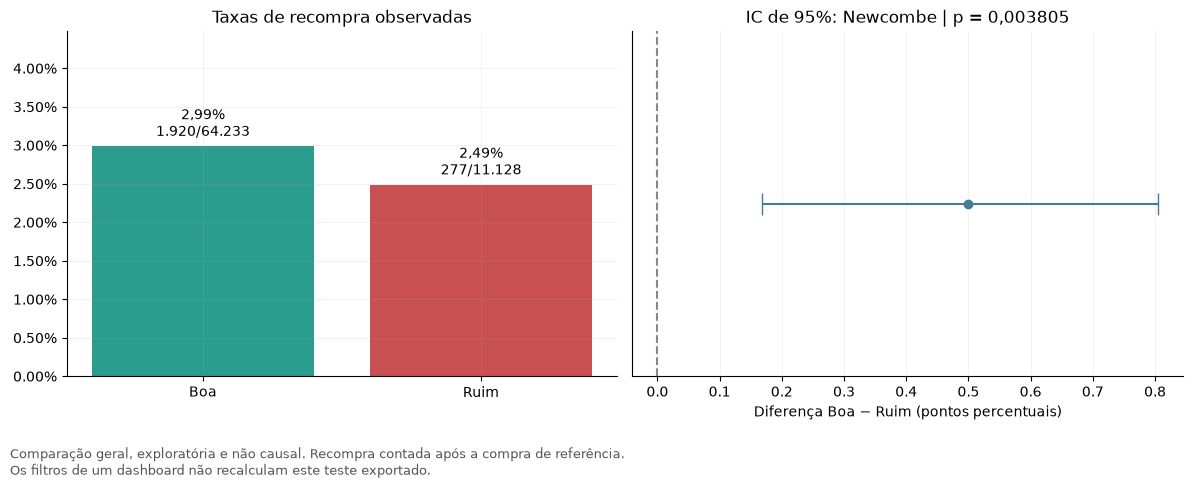

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
dados = df_grupos.loc[['Boa', 'Ruim']]
barras = eixos[0].bar(dados.index, dados['taxa_recompra'], color=['#2A9D8F', '#C95050'])
eixos[0].bar_label(barras, labels=[
    f'{t:.2%}'.replace('.', ',') + f'\n{k:,}/{n:,}'.replace(',', '.')
    for t, k, n in zip(dados['taxa_recompra'], dados['clientes_que_recompraram'], dados['total_clientes'])
], padding=4)
eixos[0].set_ylim(0, max(float(dados['taxa_recompra'].max()) * 1.5, .01))
eixos[0].yaxis.set_major_formatter(PercentFormatter(1))
eixos[0].set_title('Taxas de recompra observadas')
eixos[1].errorbar(
    diferenca_pp, 0,
    xerr=[[diferenca_pp - limite_inferior_pp], [limite_superior_pp - diferenca_pp]],
    fmt='o', color='#457B9D', capsize=8
)
eixos[1].axvline(0, color='#888888', linestyle='--')
eixos[1].set_yticks([])
eixos[1].set_xlabel('Diferença Boa − Ruim (pontos percentuais)')
eixos[1].set_title(f'IC de 95%: Newcombe | p = {p_valor:.6f}'.replace('.', ','))
for ax in eixos:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=.15)
concluir_grafico(fig, '07_teste_recompra.png',
    'Comparação geral, exploratória e não causal. Recompra contada após a compra de referência.\n'
    'Os filtros de um dashboard não recalculam este teste exportado.')


## Exportações

Salva as tabelas em Parquet e CSV e os gráficos em PNG.

In [11]:
PASTA_PARQUET = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'parquet'
PASTA_CSV = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'csv'
for pasta in (PASTA_PARQUET, PASTA_CSV, PASTA_GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)

tabelas_exportar = {
    '07_teste_recompra': df_teste_recompra,
    '07_grupos_teste_recompra': df_grupos.rename_axis('grupo').reset_index(),
}
for nome, original in tabelas_exportar.items():
    tabela = original.reset_index(drop=True).convert_dtypes()
    caminho = PASTA_PARQUET / f'{nome}.parquet'
    tabela.to_parquet(caminho, index=False)
    pd.testing.assert_frame_equal(tabela, pd.read_parquet(caminho), check_exact=True)
    tabela.to_csv(
        PASTA_CSV / f'{nome}.csv', index=False,
        sep=';', decimal=',', encoding='utf-8-sig'
    )
    print(f'Tabela exportada em Parquet e CSV: {nome} ({len(tabela)} linhas)')

for nome, conteudo in graficos_exportar.items():
    (PASTA_GRAFICOS / nome).write_bytes(conteudo)
    print(f'Gráfico exportado: {nome}')


Tabela exportada em Parquet e CSV: 07_teste_recompra (1 linhas)
Tabela exportada em Parquet e CSV: 07_grupos_teste_recompra (2 linhas)
Gráfico exportado: 07_teste_recompra.png
